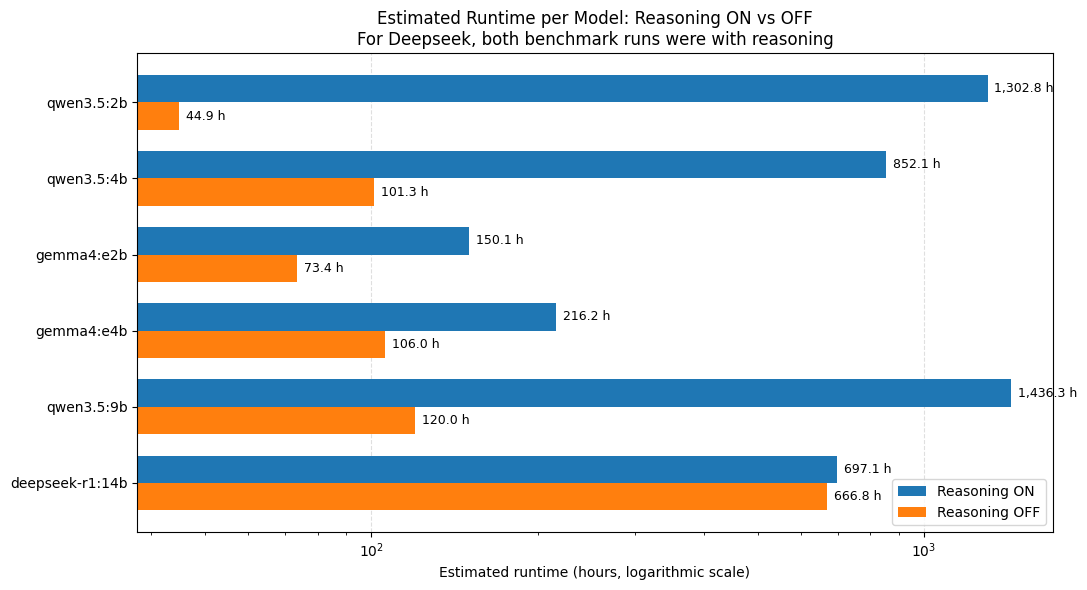

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the benchmark CSV
df = pd.read_csv("model_benchmark_summary.csv")

# 2. Assign reasoning modes
# Rows are ordered in pairs: ON first, OFF second for each model
df["reasoning"] = ["ON", "OFF"] * (len(df) // 2)

# 3. Prepare data
models = df["model"].drop_duplicates().tolist()

reasoning_on = (
    df[df["reasoning"] == "ON"]
    .set_index("model")
    .loc[models, "estimated_hours_per_model"]
)

reasoning_off = (
    df[df["reasoning"] == "OFF"]
    .set_index("model")
    .loc[models, "estimated_hours_per_model"]
)

# 4. Create grouped horizontal bar chart
y = np.arange(len(models))
height = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars_on = ax.barh(
    y - height / 2,
    reasoning_on,
    height,
    label="Reasoning ON"
)

bars_off = ax.barh(
    y + height / 2,
    reasoning_off,
    height,
    label="Reasoning OFF"
)

# 5. Labels and formatting
ax.set_yticks(y)
ax.set_yticklabels(models)
ax.invert_yaxis()

ax.set_xlabel("Estimated runtime (hours, logarithmic scale)")
ax.set_title(
    "Estimated Runtime per Model: Reasoning ON vs OFF\n" \
    "For Deepseek, both benchmark runs were with reasoning"
)

ax.set_xscale("log")
ax.legend()

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add values at the end of bars
for bars in [bars_on, bars_off]:
    for bar in bars:
        width = bar.get_width()
        ax.annotate(
            f"{width:,.1f} h",
            xy=(width, bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

plt.tight_layout()

# 6. Save and display
plt.savefig("estimated_runtime_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


Benchmark runs on all models confirmed previous findings: the whole experiment would take months to run. We will therefore fix a random subset
of true statements and cap the number of linked articles per entity, and run *every* model on exactly the same input. We will also consider 
limiting the number of models. Running the models with reasoning off is a consideration, but experimantal runs showed problems with such approach.
